In [2]:
import os
import glob
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_score, recall_score, f1_score, confusion_matrix,
    roc_auc_score, classification_report, accuracy_score
)
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")

# Keep the original dataset path from your first notebook.
RAW_DIR = "/kaggle/input/datasets/sateeshkumar6289/cicids-2017-dataset"
OUT_DIR = "/kaggle/working/processed"
os.makedirs(OUT_DIR, exist_ok=True)

TRAIN_FILE = os.path.join(OUT_DIR, "train.csv")
TEST_FILE = os.path.join(OUT_DIR, "test.csv")

In [3]:
# STEP 1: Load and combine the raw CSV files
csv_paths = sorted(glob.glob(os.path.join(RAW_DIR, "*.csv")))

if not csv_paths:
    raise FileNotFoundError(
        f"No CSV files found in {RAW_DIR}. Check RAW_DIR and update it to the folder containing the raw CICIDS2017 CSV files."
    )

print("CSV files found:")
for path in csv_paths:
    print(" -", os.path.basename(path))

df_list = [pd.read_csv(path, low_memory=False, encoding="latin1") for path in csv_paths]
df = pd.concat(df_list, ignore_index=True)
print("\nCombined shape:", df.shape)

CSV files found:
 - Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
 - Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
 - Friday-WorkingHours-Morning.pcap_ISCX.csv
 - Monday-WorkingHours.pcap_ISCX.csv
 - Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
 - Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
 - Tuesday-WorkingHours.pcap_ISCX.csv
 - Wednesday-workingHours.pcap_ISCX.csv

Combined shape: (2830743, 79)


In [4]:
# STEP 2: Clean column names by removing extra spaces
df.columns = df.columns.astype(str).str.strip()

# STEP 3: Find the source label column.
# Raw CICIDS2017 normally uses 'Label'. This fallback supports a dataset
# that already has Attack_Category instead of Label.
if "Label" in df.columns:
    label_col = "Label"
elif "Attack_Category" in df.columns:
    label_col = "Attack_Category"
else:
    raise KeyError(
        "Could not find a label column. Expected 'Label' or 'Attack_Category'. "
        f"Available columns: {df.columns.tolist()}"
    )

print("Label column:", label_col)
print(df[label_col].astype(str).str.strip().value_counts().head(20))

Label column: Label
Label
BENIGN                          2273097
DoS Hulk                         231073
PortScan                         158930
DDoS                             128027
DoS GoldenEye                     10293
FTP-Patator                        7938
SSH-Patator                        5897
DoS slowloris                      5796
DoS Slowhttptest                   5499
Bot                                1966
Web Attack ï¿½ Brute Force         1507
Web Attack ï¿½ XSS                  652
Infiltration                         36
Web Attack ï¿½ Sql Injection         21
Heartbleed                           11
Name: count, dtype: int64


In [5]:
# STEP 4: Remove duplicate rows (before splitting, as in the original notebook)
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

Duplicate rows: 308381
Shape after removing duplicates: (2522362, 79)


In [6]:
# STEP 5: Replace infinite numeric values with NaN and remove rows with invalid numeric values
numeric_cols = df.select_dtypes(include=[np.number]).columns
df[numeric_cols] = df[numeric_cols].replace([np.inf, -np.inf], np.nan)
print("Rows with missing numeric values:", df[numeric_cols].isna().any(axis=1).sum())
df = df.dropna(subset=list(numeric_cols)).reset_index(drop=True)
print("Shape after dropping rows with missing numeric values:", df.shape)

Rows with missing numeric values: 1564
Shape after dropping rows with missing numeric values: (2520798, 79)


In [7]:
# STEP 6: Drop the same identifier / leakage-risk columns used in the original notebook
id_cols = ["Flow ID", "Source IP", "Src IP", "Destination IP", "Dst IP", "Timestamp"]
identifier_cols = [c for c in id_cols if c in df.columns]
print("Identifier-like columns removed:", identifier_cols)
df = df.drop(columns=identifier_cols, errors="ignore")

Identifier-like columns removed: []


In [8]:
# STEP 7: Drop constant numeric columns, using the same rule as the original notebook
numeric_cols = df.select_dtypes(include=[np.number]).columns
constant_cols = [c for c in numeric_cols if df[c].nunique(dropna=False) <= 1 and c != label_col]
print("Constant columns removed:", constant_cols)
df = df.drop(columns=constant_cols, errors="ignore")

Constant columns removed: ['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']


In [9]:
# STEP 8: Build the target labels
# Binary_Label: 0 = BENIGN, 1 = ATTACK
# Attack_Category: original category name
labels = df[label_col].astype(str).str.strip()
df["Attack_Category"] = labels
df["Binary_Label"] = labels.str.upper().ne("BENIGN").astype("int8")

# Remove source label column if it is separate from Attack_Category.
if label_col in df.columns and label_col != "Attack_Category":
    df = df.drop(columns=[label_col])

print("\nCleaned dataset shape:", df.shape)
FEATURES = [c for c in df.columns if c not in ["Binary_Label", "Attack_Category"]]
print("Input feature count:", len(FEATURES))
print("Target columns: Binary_Label, Attack_Category")
print("\nBinary label counts:")
print(df["Binary_Label"].map({0: "BENIGN", 1: "ATTACK"}).value_counts())
print("\nAttack category counts:")
print(df["Attack_Category"].value_counts())


Cleaned dataset shape: (2520798, 72)
Input feature count: 70
Target columns: Binary_Label, Attack_Category

Binary label counts:
Binary_Label
BENIGN    2095057
ATTACK     425741
Name: count, dtype: int64

Attack category counts:
Attack_Category
BENIGN                          2095057
DoS Hulk                         172846
DDoS                             128014
PortScan                          90694
DoS GoldenEye                     10286
FTP-Patator                        5931
DoS slowloris                      5385
DoS Slowhttptest                   5228
SSH-Patator                        3219
Bot                                1948
Web Attack ï¿½ Brute Force         1470
Web Attack ï¿½ XSS                  652
Infiltration                         36
Web Attack ï¿½ Sql Injection         21
Heartbleed                           11
Name: count, dtype: int64


In [10]:
# STEP 9: Ensure feature columns are numeric and finite
# CICIDS2017 traffic features should be numeric. Any unexpected non-numeric
# feature values are converted to NaN and removed, consistent with cleaning.
FEATURES = [c for c in df.columns if c not in ["Binary_Label", "Attack_Category"]]
for col in FEATURES:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df[FEATURES] = df[FEATURES].replace([np.inf, -np.inf], np.nan)
before_rows = len(df)
df = df.dropna(subset=FEATURES + ["Binary_Label", "Attack_Category"]).reset_index(drop=True)
print("Rows removed due to invalid feature/target values:", before_rows - len(df))
print("Final cleaned shape:", df.shape)
print("Final input feature count:", len(FEATURES))

Rows removed due to invalid feature/target values: 0
Final cleaned shape: (2520798, 72)
Final input feature count: 70


In [11]:
# STEP 10: Split into training and testing data (80:20 only; no validation set)
X = df[FEATURES]
y_binary = df["Binary_Label"]
y_category = df["Attack_Category"]

X_train, X_test, y_train, y_test, cat_train, cat_test = train_test_split(
    X, y_binary, y_category,
    test_size=0.20,
    random_state=42,
    stratify=y_category
)

print("Train rows:", len(X_train), "| Test rows:", len(X_test))
print("Train features:", X_train.shape[1], "| Test features:", X_test.shape[1])
print("Train categories:", cat_train.nunique(), "| Test categories:", cat_test.nunique())

Train rows: 2016638 | Test rows: 504160
Train features: 70 | Test features: 70
Train categories: 15 | Test categories: 15


In [12]:
# STEP 11: Scale features (fit on train only, apply to test)
scaler = StandardScaler()
scaler.fit(X_train)

X_train_scaled = pd.DataFrame(
    scaler.transform(X_train), columns=FEATURES, index=X_train.index
).reset_index(drop=True)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test), columns=FEATURES, index=X_test.index
).reset_index(drop=True)

# Add both targets to the saved files
X_train_scaled["Binary_Label"] = y_train.reset_index(drop=True).astype("int8")
X_train_scaled["Attack_Category"] = cat_train.reset_index(drop=True).astype(str)
X_test_scaled["Binary_Label"] = y_test.reset_index(drop=True).astype("int8")
X_test_scaled["Attack_Category"] = cat_test.reset_index(drop=True).astype(str)

X_train_scaled.to_csv(TRAIN_FILE, index=False)
X_test_scaled.to_csv(TEST_FILE, index=False)

print("Saved training data:", TRAIN_FILE)
print("Saved testing data:", TEST_FILE)
print("Training file shape:", X_train_scaled.shape)
print("Testing file shape:", X_test_scaled.shape)

Saved training data: /kaggle/working/processed/train.csv
Saved testing data: /kaggle/working/processed/test.csv
Training file shape: (2016638, 72)
Testing file shape: (504160, 72)


In [13]:
# STEP 12: Confirm the saved files and feature count
train_check = pd.read_csv(TRAIN_FILE, nrows=5)
test_check = pd.read_csv(TEST_FILE, nrows=5)
print("Training columns:", len(train_check.columns))
print("Testing columns:", len(test_check.columns))
print("Input features (excluding two target columns):", len(train_check.columns) - 2)
print("First few feature names:", [c for c in train_check.columns if c not in ["Binary_Label", "Attack_Category"]][:10])

Training columns: 72
Testing columns: 72
Input features (excluding two target columns): 70
First few feature names: ['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std']


In [14]:
# Load the preprocessed training data
eda_df = pd.read_csv(TRAIN_FILE)
print("Loaded training data shape:", eda_df.shape)

Loaded training data shape: (2016638, 72)


Binary label counts:
Binary_Label
BENIGN    1676045
ATTACK     340593
Name: count, dtype: int64

Binary label percentage:
Binary_Label
BENIGN    83.11
ATTACK    16.89
Name: proportion, dtype: float64

Attack category counts:
Attack_Category
BENIGN                          1676045
DoS Hulk                         138277
DDoS                             102411
PortScan                          72555
DoS GoldenEye                      8229
FTP-Patator                        4745
DoS slowloris                      4308
DoS Slowhttptest                   4182
SSH-Patator                        2575
Bot                                1558
Web Attack ï¿½ Brute Force         1176
Web Attack ï¿½ XSS                  522
Infiltration                         29
Web Attack ï¿½ Sql Injection         17
Heartbleed                            9
Name: count, dtype: int64


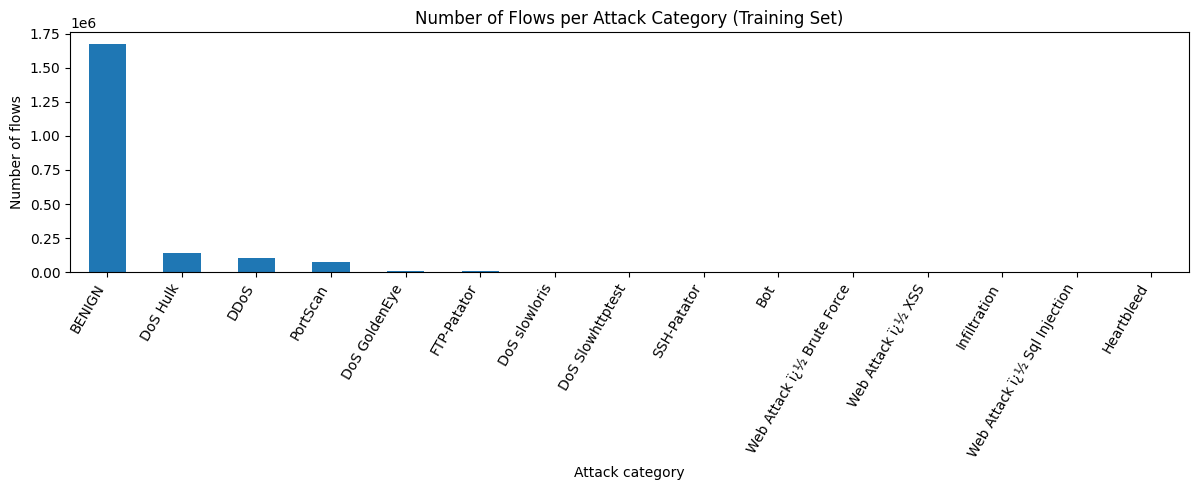

In [15]:
# PART 1: Binary class distribution
binary_counts = eda_df["Binary_Label"].value_counts().sort_index()
binary_percent = eda_df["Binary_Label"].value_counts(normalize=True).sort_index() * 100

print("Binary label counts:")
print(binary_counts.rename(index={0: "BENIGN", 1: "ATTACK"}))
print("\nBinary label percentage:")
print(binary_percent.rename(index={0: "BENIGN", 1: "ATTACK"}).round(2))

print("\nAttack category counts:")
print(eda_df["Attack_Category"].value_counts())

plt.figure(figsize=(12, 5))
eda_df["Attack_Category"].value_counts().plot(kind="bar")
plt.title("Number of Flows per Attack Category (Training Set)")
plt.ylabel("Number of flows")
plt.xlabel("Attack category")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.savefig("/kaggle/working/class_distribution.png", dpi=150)
plt.show()

Features being compared: ['Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Flow Bytes/s', 'Flow Packets/s']

Flow Duration
  BENIGN mean (scaled): -0.1257
  ATTACK mean (scaled): 0.6184

Total Fwd Packets
  BENIGN mean (scaled): 0.0014
  ATTACK mean (scaled): -0.0069

Total Backward Packets
  BENIGN mean (scaled): 0.0015
  ATTACK mean (scaled): -0.0072

Flow Bytes/s
  BENIGN mean (scaled): 0.0100
  ATTACK mean (scaled): -0.0490

Flow Packets/s
  BENIGN mean (scaled): 0.0309
  ATTACK mean (scaled): -0.1520


<Figure size 600x400 with 0 Axes>

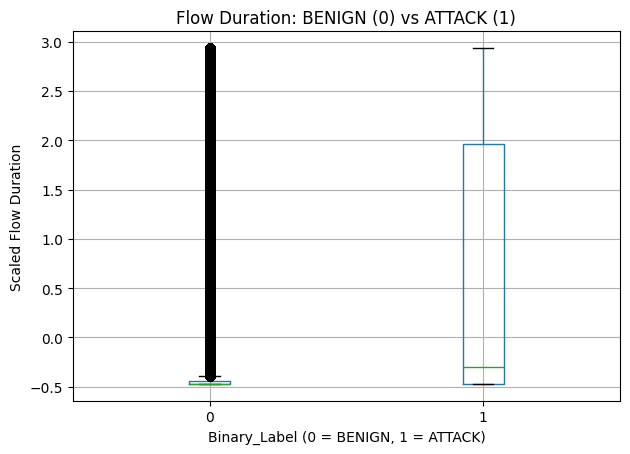

<Figure size 600x400 with 0 Axes>

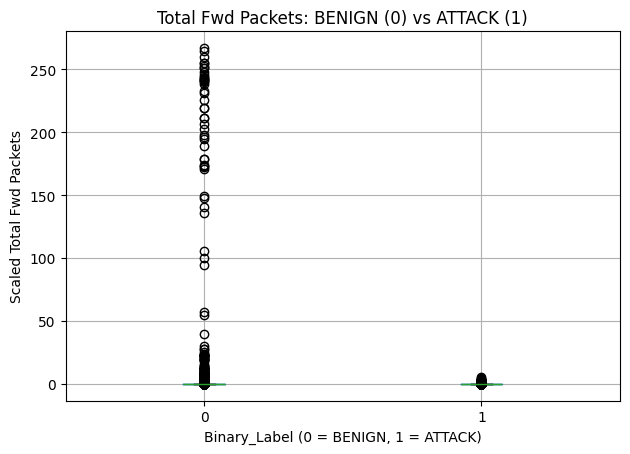

<Figure size 600x400 with 0 Axes>

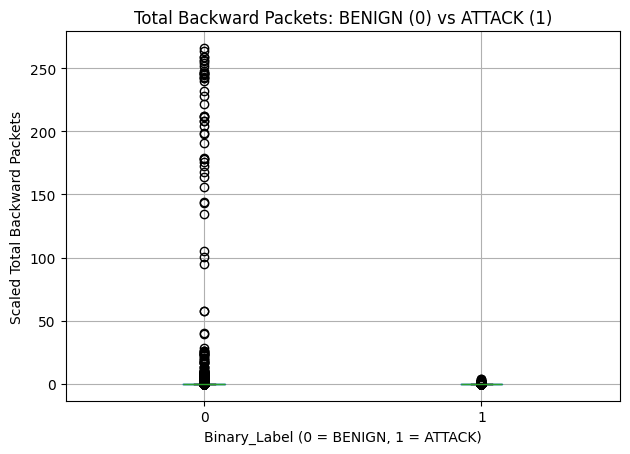

<Figure size 600x400 with 0 Axes>

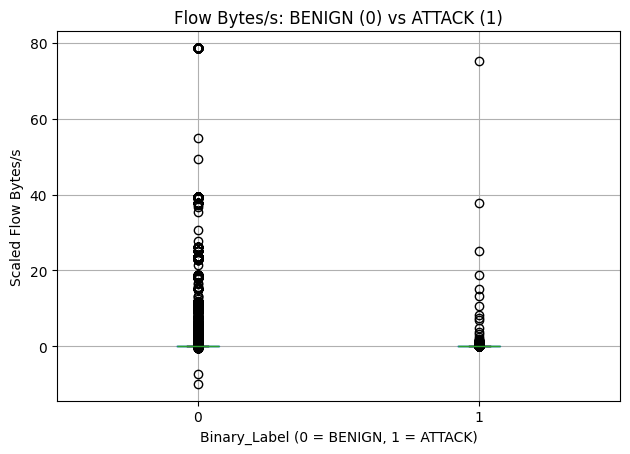

<Figure size 600x400 with 0 Axes>

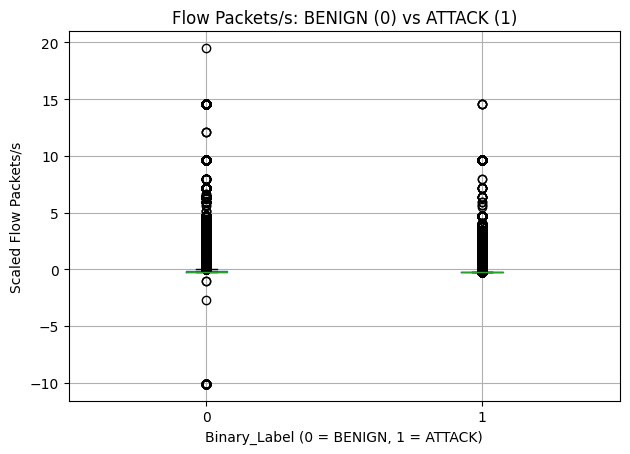

In [16]:
# PART 2: Compare selected features between benign and attack traffic
features_to_check = [
    "Flow Duration",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Flow Bytes/s",
    "Flow Packets/s",
]
features_to_check = [f for f in features_to_check if f in eda_df.columns]
print("Features being compared:", features_to_check)

for feature in features_to_check:
    normal_avg = eda_df.loc[eda_df["Binary_Label"] == 0, feature].mean()
    attack_avg = eda_df.loc[eda_df["Binary_Label"] == 1, feature].mean()
    print(f"\n{feature}")
    print(f"  BENIGN mean (scaled): {normal_avg:.4f}")
    print(f"  ATTACK mean (scaled): {attack_avg:.4f}")

for feature in features_to_check:
    plt.figure(figsize=(6, 4))
    eda_df.boxplot(column=feature, by="Binary_Label")
    plt.title(f"{feature}: BENIGN (0) vs ATTACK (1)")
    plt.suptitle("")
    plt.xlabel("Binary_Label (0 = BENIGN, 1 = ATTACK)")
    plt.ylabel(f"Scaled {feature}")
    plt.tight_layout()
    safe_name = feature.replace("/", "_").replace(" ", "_")
    plt.savefig(f"/kaggle/working/boxplot_{safe_name}.png", dpi=150)
    plt.show()

Top categories being compared: ['BENIGN', 'DoS Hulk', 'DDoS', 'PortScan', 'DoS GoldenEye', 'FTP-Patator']


<Figure size 900x500 with 0 Axes>

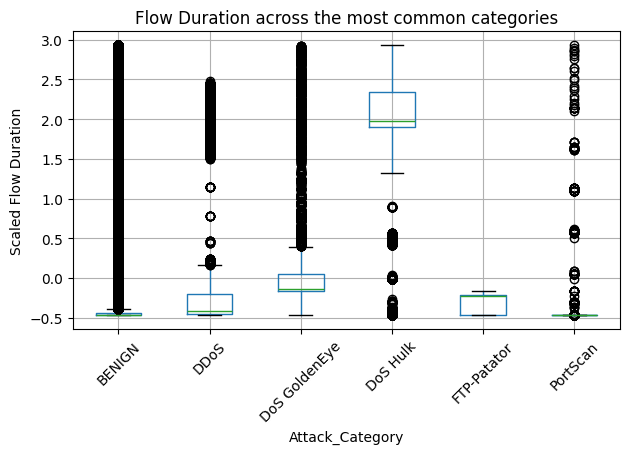

<Figure size 900x500 with 0 Axes>

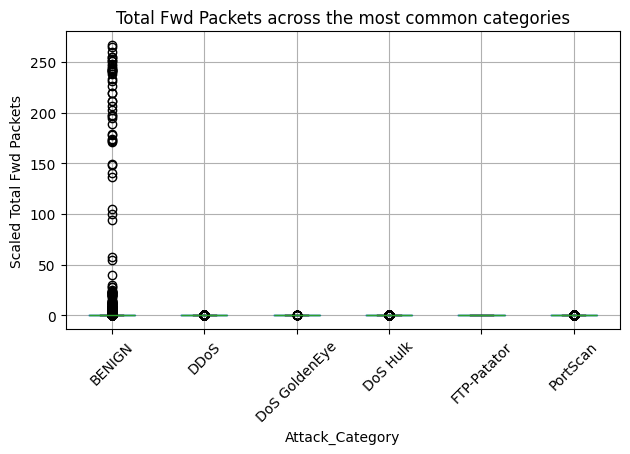

<Figure size 900x500 with 0 Axes>

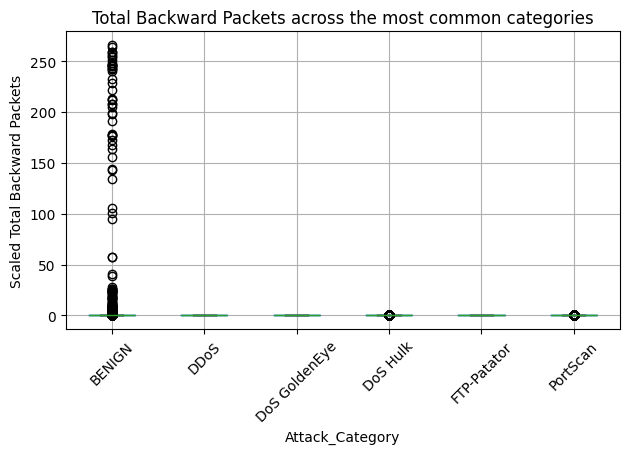

<Figure size 900x500 with 0 Axes>

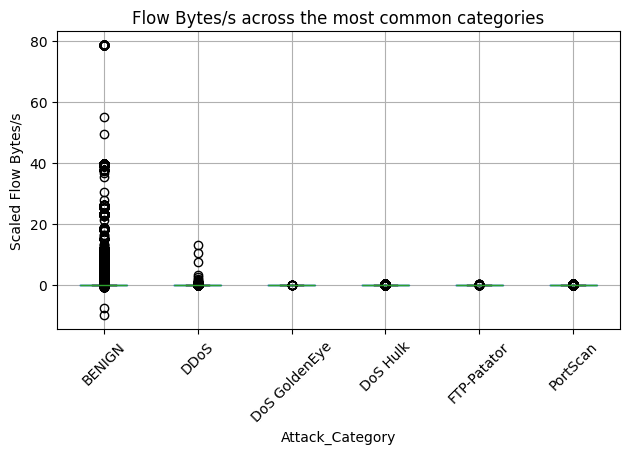

<Figure size 900x500 with 0 Axes>

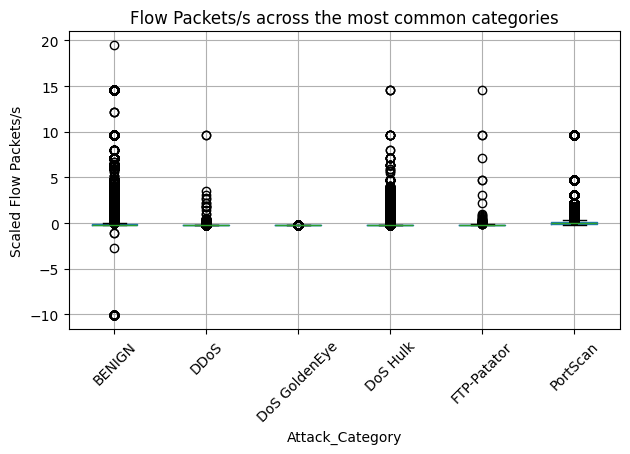

In [17]:
# PART 3: Compare selected features across the most common attack categories
# Limit plots to the six most common categories so that the charts remain readable.
top_categories = eda_df["Attack_Category"].value_counts().head(6).index.tolist()
print("Top categories being compared:", top_categories)
df_top = eda_df[eda_df["Attack_Category"].isin(top_categories)]

for feature in features_to_check:
    plt.figure(figsize=(9, 5))
    df_top.boxplot(column=feature, by="Attack_Category", rot=45)
    plt.title(f"{feature} across the most common categories")
    plt.suptitle("")
    plt.ylabel(f"Scaled {feature}")
    plt.tight_layout()
    safe_name = feature.replace("/", "_").replace(" ", "_")
    plt.savefig(f"/kaggle/working/category_boxplot_{safe_name}.png", dpi=150)
    plt.show()

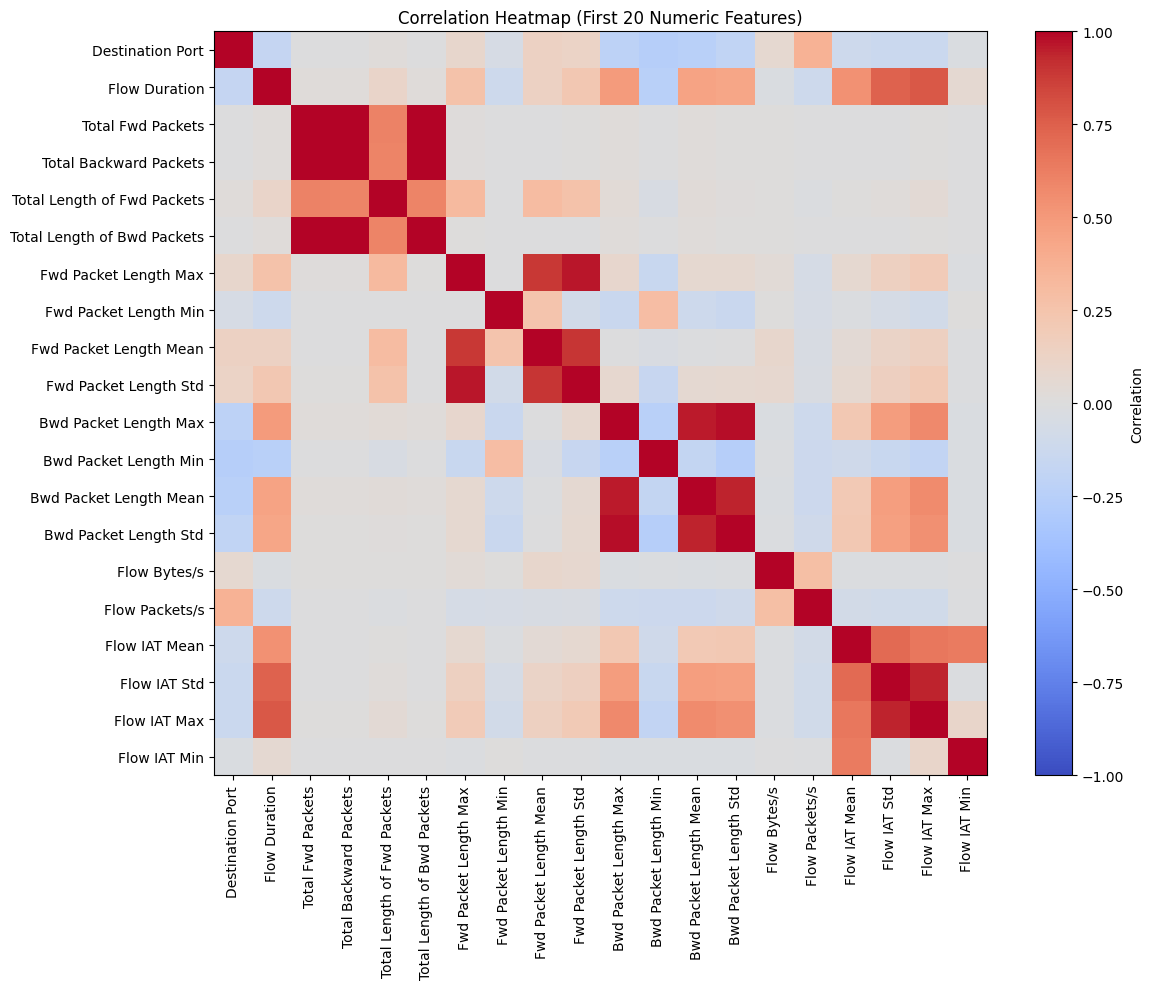

In [18]:
# PART 4: Correlation heatmap for a subset of numeric features
numeric_df = eda_df.select_dtypes(include=[np.number]).drop(columns=["Binary_Label"], errors="ignore")
columns_to_plot = list(numeric_df.columns[:20])
correlation_matrix = numeric_df[columns_to_plot].corr()

plt.figure(figsize=(12, 10))
plt.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
plt.colorbar(label="Correlation")
plt.xticks(range(len(columns_to_plot)), columns_to_plot, rotation=90)
plt.yticks(range(len(columns_to_plot)), columns_to_plot)
plt.title("Correlation Heatmap (First 20 Numeric Features)")
plt.tight_layout()
plt.savefig("/kaggle/working/correlation_heatmap.png", dpi=150)
plt.show()

In [19]:
# Load train and test files
train_df = pd.read_csv(TRAIN_FILE)
test_df = pd.read_csv(TEST_FILE)

columns_to_drop = ["Binary_Label", "Attack_Category"]
X_train = train_df.drop(columns=columns_to_drop)
y_train = train_df["Binary_Label"].astype(int)
X_test = test_df.drop(columns=columns_to_drop)
y_test = test_df["Binary_Label"].astype(int)

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)
print("Number of input features:", X_train.shape[1])

Train shape: (2016638, 72)
Test shape: (504160, 72)
Number of input features: 70


In [20]:
def train_and_evaluate(model, model_name, X_train, y_train, X_test, y_test):
    print("\n" + "=" * 65)
    print("MODEL:", model_name)
    print("=" * 65)

    start = time.time()
    model.fit(X_train, y_train)
    training_time = time.time() - start

    start = time.time()
    y_pred = model.predict(X_test)
    prediction_time = time.time() - start

    y_prob = model.predict_proba(X_test)[:, 1]
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_test, y_prob)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
    fpr = fp / (fp + tn) if (fp + tn) else 0.0

    print(f"Training time:       {training_time:.2f} seconds")
    print(f"Prediction time:     {prediction_time:.4f} seconds")
    print(f"Accuracy:            {accuracy_score(y_test, y_pred):.4f}")
    print(f"Precision:           {precision:.4f}")
    print(f"Recall:              {recall:.4f} (attack detection rate)")
    print(f"F1-score:            {f1:.4f}")
    print(f"False Positive Rate: {fpr:.4f}")
    print(f"ROC-AUC:             {roc_auc:.4f}")

    print("\nConfusion matrix (rows = actual, columns = predicted):")
    print(pd.DataFrame(
        [[tn, fp], [fn, tp]],
        index=["Actual BENIGN", "Actual ATTACK"],
        columns=["Predicted BENIGN", "Predicted ATTACK"]
    ))
    print("\nClassification report:")
    print(classification_report(y_test, y_pred, labels=[0, 1], target_names=["BENIGN", "ATTACK"], zero_division=0))

    return {
        "model_name": model_name,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision,
        "recall": recall,
        "f1_score": f1,
        "false_positive_rate": fpr,
        "roc_auc": roc_auc,
        "training_time_sec": training_time,
        "prediction_time_sec": prediction_time,
    }

In [21]:
# Train and evaluate all three models on the same train/test split
results = []

log_reg_model = LogisticRegression(max_iter=1000, n_jobs=-1)
results.append(train_and_evaluate(log_reg_model, "Logistic Regression", X_train, y_train, X_test, y_test))

random_forest_model = RandomForestClassifier(
    n_estimators=100, random_state=42, n_jobs=-1
)
results.append(train_and_evaluate(random_forest_model, "Random Forest", X_train, y_train, X_test, y_test))

xgboost_model = XGBClassifier(
    n_estimators=100,
    random_state=42,
    eval_metric="logloss",
    n_jobs=-1,
)
results.append(train_and_evaluate(xgboost_model, "XGBoost", X_train, y_train, X_test, y_test))

results_df = pd.DataFrame(results).set_index("model_name")
print("\nModel comparison:")
print(results_df.round(4))
results_df.to_csv("/kaggle/working/phase3_model_comparison.csv")
print("Saved: /kaggle/working/phase3_model_comparison.csv")


MODEL: Logistic Regression
Training time:       140.90 seconds
Prediction time:     0.0832 seconds
Accuracy:            0.9572
Precision:           0.8817
Recall:              0.8623 (attack detection rate)
F1-score:            0.8719
False Positive Rate: 0.0235
ROC-AUC:             0.9880

Confusion matrix (rows = actual, columns = predicted):
               Predicted BENIGN  Predicted ATTACK
Actual BENIGN            409157              9855
Actual ATTACK             11724             73424

Classification report:
              precision    recall  f1-score   support

      BENIGN       0.97      0.98      0.97    419012
      ATTACK       0.88      0.86      0.87     85148

    accuracy                           0.96    504160
   macro avg       0.93      0.92      0.92    504160
weighted avg       0.96      0.96      0.96    504160


MODEL: Random Forest
Training time:       565.39 seconds
Prediction time:     2.5675 seconds
Accuracy:            0.9986
Precision:           0.9964
R

In [22]:
# Load train and test data
train_df = pd.read_csv(TRAIN_FILE)
test_df = pd.read_csv(TEST_FILE)

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)
print("\nCategory counts in training data:")
print(train_df["Attack_Category"].value_counts())

# Keep every category; no MIN_SAMPLES filter
train_filtered = train_df.copy()
test_filtered = test_df.copy()

columns_to_drop = ["Binary_Label", "Attack_Category"]
X_train_multi = train_filtered.drop(columns=columns_to_drop)
X_test_multi = test_filtered.drop(columns=columns_to_drop)

# Fit LabelEncoder on training labels. Stratifying the Phase 1 split by
# Attack_Category is intended to ensure every category appears in train and test.
label_encoder = LabelEncoder()
y_train_multi = label_encoder.fit_transform(train_filtered["Attack_Category"].astype(str))

unknown_test_categories = sorted(
    set(test_filtered["Attack_Category"].astype(str)) - set(label_encoder.classes_)
)
if unknown_test_categories:
    raise ValueError(
        "These test categories are missing from training data: " + str(unknown_test_categories)
    )
y_test_multi = label_encoder.transform(test_filtered["Attack_Category"].astype(str))
class_names = label_encoder.classes_

print("\nNumber of categories retained:", len(class_names))
print("Class number -> category name:")
for number, name in enumerate(class_names):
    print(f"{number} -> {name}")

Train shape: (2016638, 72)
Test shape: (504160, 72)

Category counts in training data:
Attack_Category
BENIGN                          1676045
DoS Hulk                         138277
DDoS                             102411
PortScan                          72555
DoS GoldenEye                      8229
FTP-Patator                        4745
DoS slowloris                      4308
DoS Slowhttptest                   4182
SSH-Patator                        2575
Bot                                1558
Web Attack ï¿½ Brute Force         1176
Web Attack ï¿½ XSS                  522
Infiltration                         29
Web Attack ï¿½ Sql Injection         17
Heartbleed                            9
Name: count, dtype: int64

Number of categories retained: 15
Class number -> category name:
0 -> BENIGN
1 -> Bot
2 -> DDoS
3 -> DoS GoldenEye
4 -> DoS Hulk
5 -> DoS Slowhttptest
6 -> DoS slowloris
7 -> FTP-Patator
8 -> Heartbleed
9 -> Infiltration
10 -> PortScan
11 -> SSH-Patator
12 -> Web Attack

In [23]:
# Train multiclass XGBoost
print("Training multiclass XGBoost model...")
multiclass_model = XGBClassifier(
    objective="multi:softprob",
    num_class=len(class_names),
    n_estimators=100,
    random_state=42,
    eval_metric="mlogloss",
    n_jobs=-1,
)
multiclass_model.fit(X_train_multi, y_train_multi)
y_pred_multi = multiclass_model.predict(X_test_multi).astype(int)
print("Multiclass training complete.")

Training multiclass XGBoost model...
Multiclass training complete.


In [24]:
# STEP 1: Multiclass confusion matrix
cm = confusion_matrix(y_test_multi, y_pred_multi, labels=np.arange(len(class_names)))
cm_df = pd.DataFrame(cm, index=class_names, columns=class_names)
print("Multiclass confusion matrix (rows = actual, columns = predicted):")
print(cm_df)
cm_df.to_csv("/kaggle/working/phase4_confusion_matrix.csv")
print("Saved: /kaggle/working/phase4_confusion_matrix.csv")

Multiclass confusion matrix (rows = actual, columns = predicted):
                              BENIGN  Bot   DDoS  DoS GoldenEye  DoS Hulk  \
BENIGN                        417745   83     80             95       215   
Bot                              120  270      0              0         0   
DDoS                              89    0  25505              1         3   
DoS GoldenEye                     93    0      2           1959         0   
DoS Hulk                         217    0      0              3     34305   
DoS Slowhttptest                 119    1      2              6        34   
DoS slowloris                     53    0      0              0         0   
FTP-Patator                       29    0      0              0         0   
Heartbleed                         2    0      0              0         0   
Infiltration                       7    0      0              0         0   
PortScan                          75    0      6              1        10   
SSH-Patato

In [25]:
# STEP 2: Per-class precision, recall, F1-score, and support
report_dict = classification_report(
    y_test_multi,
    y_pred_multi,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    output_dict=True,
    zero_division=0,
)
report_df = pd.DataFrame(report_dict).transpose()
print(report_df)
report_df.to_csv("/kaggle/working/phase4_per_class_report.csv")
print("Saved: /kaggle/working/phase4_per_class_report.csv")

                              precision    recall  f1-score        support
BENIGN                         0.997848  0.996976  0.997412  419012.000000
Bot                            0.762712  0.692308  0.725806     390.000000
DDoS                           0.996289  0.996172  0.996231   25603.000000
DoS GoldenEye                  0.948209  0.952358  0.950279    2057.000000
DoS Hulk                       0.992306  0.992363  0.992334   34569.000000
DoS Slowhttptest               0.756238  0.753346  0.754789    1046.000000
DoS slowloris                  0.933204  0.895079  0.913744    1077.000000
FTP-Patator                    0.966555  0.974705  0.970613    1186.000000
Heartbleed                     0.000000  0.000000  0.000000       2.000000
Infiltration                   0.000000  0.000000  0.000000       7.000000
PortScan                       0.982705  0.992999  0.987825   18139.000000
SSH-Patator                    0.868421  0.922360  0.894578     644.000000
Web Attack ï¿½ Brute Forc

In [26]:
# STEP 3: Show best and worst detected categories by recall
class_only_report = report_df.loc[list(class_names)].sort_values("recall", ascending=False)
print("\nBest detected categories by recall:")
print(class_only_report[["precision", "recall", "f1-score", "support"]].head(5))
print("\nWorst detected categories by recall:")
print(class_only_report[["precision", "recall", "f1-score", "support"]].tail(5))




Best detected categories by recall:
             precision    recall  f1-score   support
BENIGN        0.997848  0.996976  0.997412  419012.0
DDoS          0.996289  0.996172  0.996231   25603.0
PortScan      0.982705  0.992999  0.987825   18139.0
DoS Hulk      0.992306  0.992363  0.992334   34569.0
FTP-Patator   0.966555  0.974705  0.970613    1186.0

Worst detected categories by recall:
                              precision    recall  f1-score  support
Web Attack ï¿½ Brute Force     0.585799  0.673469  0.626582    294.0
Web Attack ï¿½ Sql Injection   0.025974  0.500000  0.049383      4.0
Web Attack ï¿½ XSS             0.300000  0.300000  0.300000    130.0
Infiltration                   0.000000  0.000000  0.000000      7.0
Heartbleed                     0.000000  0.000000  0.000000      2.0


In [27]:
# ============================================================
# PHASE 5: FEATURE SELECTION XGBoost feature selection
# CELL 1: CREATE TRAINING AND VALIDATION SETS
# ============================================================

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score
from xgboost import XGBClassifier

print("Original training shape:", X_train_multi.shape)
print("Original test shape:", X_test_multi.shape)
print("Number of input features:", X_train_multi.shape[1])

# Split indices instead of splitting the full dataset directly
train_indices, val_indices = train_test_split(
    np.arange(len(y_train_multi)),
    test_size=0.20,
    random_state=42,
    stratify=y_train_multi
)

X_inner_train = X_train_multi.iloc[train_indices]
X_val = X_train_multi.iloc[val_indices]

y_inner_train = y_train_multi[train_indices]
y_val = y_train_multi[val_indices]

print("\nInner training shape:", X_inner_train.shape)
print("Validation shape:", X_val.shape)

print("\nTraining records:", len(y_inner_train))
print("Validation records:", len(y_val))
print("Number of classes:", len(class_names))

Original training shape: (2016638, 70)
Original test shape: (504160, 70)
Number of input features: 70

Inner training shape: (1613310, 70)
Validation shape: (403328, 70)

Training records: 1613310
Validation records: 403328
Number of classes: 15


In [28]:
# ============================================================
# PHASE 5: FEATURE SELECTION
#  FEATURE IMPORTANCE
# ============================================================

feature_model = XGBClassifier(
    objective="multi:softprob",
    num_class=len(class_names),
    n_estimators=50,
    max_depth=6,
    random_state=42,
    eval_metric="mlogloss",
    n_jobs=-1,
    tree_method="hist"
)

print("Training XGBoost to calculate feature importance...")

feature_model.fit(
    X_inner_train,
    y_inner_train
)

# Rank the original features
feature_importance_df = pd.DataFrame({
    "Feature": X_inner_train.columns,
    "Importance": feature_model.feature_importances_
})

feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("\nTop 20 important features:")
print(feature_importance_df.head(20).to_string(index=False))

# Save the ranking
feature_importance_df.to_csv(
    "/kaggle/working/phase5_feature_importance.csv",
    index=False
)

print("\nFeature importance saved successfully.")

Training XGBoost to calculate feature importance...

Top 20 important features:
                    Feature  Importance
     Packet Length Variance    0.686496
          Fwd Header Length    0.046935
             PSH Flag Count    0.027899
             Flow Packets/s    0.025288
     Total Backward Packets    0.022060
              Flow Duration    0.021699
               Flow IAT Min    0.019822
              Flow IAT Mean    0.018645
               Fwd IAT Mean    0.017975
              Bwd IAT Total    0.013035
              Bwd Packets/s    0.012794
       min_seg_size_forward    0.010464
                Fwd IAT Min    0.009461
Total Length of Fwd Packets    0.008297
               Flow Bytes/s    0.006809
                  Idle Mean    0.006549
      Bwd Packet Length Min    0.006414
     Fwd Packet Length Mean    0.006255
          Min Packet Length    0.004140
          Bwd Header Length    0.004130

Feature importance saved successfully.


In [29]:
# ============================================================
# PHASE 5: FEATURE SELECTION
# CELL 3: COMPARE FEATURE COUNTS
# ============================================================

feature_counts = [
    10,
    20,
    30,
    X_inner_train.shape[1]
]

# Remove duplicate counts, if any
feature_counts = sorted(set(feature_counts))

phase5_results = []

for n_features in feature_counts:

    selected_features = (
        feature_importance_df["Feature"]
        .head(n_features)
        .tolist()
    )

    print("\n" + "=" * 65)
    print("Testing", n_features, "features")
    print("=" * 65)

    model = XGBClassifier(
        objective="multi:softprob",
        num_class=len(class_names),
        n_estimators=50,
        max_depth=6,
        random_state=42,
        eval_metric="mlogloss",
        n_jobs=-1,
        tree_method="hist"
    )

    model.fit(
        X_inner_train[selected_features],
        y_inner_train
    )

    val_pred = model.predict(
        X_val[selected_features]
    ).astype(int)

    accuracy = accuracy_score(y_val, val_pred)

    macro_f1 = f1_score(
        y_val,
        val_pred,
        average="macro",
        zero_division=0
    )

    weighted_f1 = f1_score(
        y_val,
        val_pred,
        average="weighted",
        zero_division=0
    )

    phase5_results.append({
        "Number_of_Features": n_features,
        "Accuracy": accuracy,
        "Macro_F1": macro_f1,
        "Weighted_F1": weighted_f1
    })

    print(f"Accuracy:    {accuracy:.4f}")
    print(f"Macro F1:    {macro_f1:.4f}")
    print(f"Weighted F1: {weighted_f1:.4f}")

phase5_results_df = pd.DataFrame(phase5_results)

print("\nPHASE 5 RESULTS")
print(phase5_results_df.to_string(index=False))

phase5_results_df.to_csv(
    "/kaggle/working/phase5_feature_selection_results.csv",
    index=False
)

print("\nResults saved to phase5_feature_selection_results.csv")


Testing 10 features
Accuracy:    0.9914
Macro F1:    0.6194
Weighted F1: 0.9913

Testing 20 features
Accuracy:    0.9072
Macro F1:    0.2392
Weighted F1: 0.9165

Testing 30 features
Accuracy:    0.9442
Macro F1:    0.2737
Weighted F1: 0.9450

Testing 70 features
Accuracy:    0.9949
Macro F1:    0.7179
Weighted F1: 0.9951

PHASE 5 RESULTS
 Number_of_Features  Accuracy  Macro_F1  Weighted_F1
                 10  0.991411  0.619410     0.991263
                 20  0.907249  0.239208     0.916528
                 30  0.944219  0.273699     0.944979
                 70  0.994880  0.717903     0.995101

Results saved to phase5_feature_selection_results.csv


In [30]:
# ============================================================
# PHASE 6: CLASS IMBALANCE HANDLING
# CELL 1: SELECT FEATURES
# ============================================================

best_row = phase5_results_df.loc[
    phase5_results_df["Macro_F1"].idxmax()
]

best_n_features = int(
    best_row["Number_of_Features"]
)

selected_features = (
    feature_importance_df["Feature"]
    .head(best_n_features)
    .tolist()
)

print("Selected number of features:", best_n_features)

print("\nSelected features:")
for feature in selected_features:
    print(feature)

print("\nTraining class distribution:")
print(
    pd.Series(y_inner_train)
    .map(dict(enumerate(class_names)))
    .value_counts()
)

Selected number of features: 70

Selected features:
Packet Length Variance
Fwd Header Length
PSH Flag Count
Flow Packets/s
Total Backward Packets
Flow Duration
Flow IAT Min
Flow IAT Mean
Fwd IAT Mean
Bwd IAT Total
Bwd Packets/s
min_seg_size_forward
Fwd IAT Min
Total Length of Fwd Packets
Flow Bytes/s
Idle Mean
Bwd Packet Length Min
Fwd Packet Length Mean
Min Packet Length
Bwd Header Length
Max Packet Length
Init_Win_bytes_forward
Bwd IAT Mean
Active Min
Fwd Packets/s
Bwd IAT Max
Packet Length Std
Flow IAT Max
Fwd IAT Std
Idle Min
Active Mean
act_data_pkt_fwd
Total Length of Bwd Packets
Active Max
Init_Win_bytes_backward
Fwd IAT Total
Flow IAT Std
Idle Max
Idle Std
Fwd Packet Length Std
Fwd Packet Length Max
Bwd Packet Length Max
Average Packet Size
Down/Up Ratio
Bwd Packet Length Mean
Fwd IAT Max
Active Std
Fwd Packet Length Min
Fwd PSH Flags
Destination Port
Bwd IAT Min
Bwd IAT Std
Packet Length Mean
Bwd Packet Length Std
URG Flag Count
Total Fwd Packets
FIN Flag Count
ACK Flag Count


In [31]:
# ============================================================
# PHASE 6: CLASS IMBALANCE HANDLING
# CELL 2: MODEL COMPARISON
# ============================================================

from sklearn.utils.class_weight import compute_sample_weight

# Calculate weights using only the inner training labels
sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_inner_train
)

print("Training sample weights calculated.")
print("Training records:", len(sample_weights))


# ------------------------------------------------------------
# MODEL 1: ORDINARY XGBOOST
# ------------------------------------------------------------

baseline_model = XGBClassifier(
    objective="multi:softprob",
    num_class=len(class_names),
    n_estimators=50,
    max_depth=6,
    random_state=42,
    eval_metric="mlogloss",
    n_jobs=-1,
    tree_method="hist"
)

print("\nTraining ordinary XGBoost...")

baseline_model.fit(
    X_inner_train[selected_features],
    y_inner_train
)

baseline_pred = baseline_model.predict(
    X_val[selected_features]
).astype(int)

print("Ordinary XGBoost completed.")


# ------------------------------------------------------------
# MODEL 2: CLASS-WEIGHTED XGBOOST
# ------------------------------------------------------------

weighted_model = XGBClassifier(
    objective="multi:softprob",
    num_class=len(class_names),
    n_estimators=50,
    max_depth=6,
    random_state=42,
    eval_metric="mlogloss",
    n_jobs=-1,
    tree_method="hist"
)

print("\nTraining class-weighted XGBoost...")

weighted_model.fit(
    X_inner_train[selected_features],
    y_inner_train,
    sample_weight=sample_weights
)

weighted_pred = weighted_model.predict(
    X_val[selected_features]
).astype(int)

print("Class-weighted XGBoost completed.")


# ------------------------------------------------------------
# COMPARE BOTH MODELS
# ------------------------------------------------------------

phase6_results = []

for model_name, predictions in [
    ("Ordinary XGBoost", baseline_pred),
    ("Class-Weighted XGBoost", weighted_pred)
]:

    accuracy = accuracy_score(y_val, predictions)

    macro_f1 = f1_score(
        y_val,
        predictions,
        average="macro",
        zero_division=0
    )

    weighted_f1 = f1_score(
        y_val,
        predictions,
        average="weighted",
        zero_division=0
    )

    phase6_results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Macro_F1": macro_f1,
        "Weighted_F1": weighted_f1
    })

phase6_results_df = pd.DataFrame(phase6_results)

print("\nPHASE 6 RESULTS")
print(phase6_results_df.to_string(index=False))

phase6_results_df.to_csv(
    "/kaggle/working/phase6_imbalance_results.csv",
    index=False
)

print("\nResults saved to phase6_imbalance_results.csv")

Training sample weights calculated.
Training records: 1613310

Training ordinary XGBoost...
Ordinary XGBoost completed.

Training class-weighted XGBoost...
Class-weighted XGBoost completed.

PHASE 6 RESULTS
                 Model  Accuracy  Macro_F1  Weighted_F1
      Ordinary XGBoost  0.994880  0.717903     0.995101
Class-Weighted XGBoost  0.998356  0.868915     0.998438

Results saved to phase6_imbalance_results.csv


In [32]:
# ============================================================
# PHASE 6: CLASS IMBALANCE HANDLING
# CELL 3: PER-CLASS EVALUATION
# ============================================================

baseline_report = classification_report(
    y_val,
    baseline_pred,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

weighted_report = classification_report(
    y_val,
    weighted_pred,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

baseline_report_df = pd.DataFrame(
    baseline_report
).transpose()

weighted_report_df = pd.DataFrame(
    weighted_report
).transpose()

# Compare precision, recall, and F1 for every attack class
per_class_comparison = pd.DataFrame({
    "Baseline_Precision": baseline_report_df.loc[
        list(class_names), "precision"
    ],
    "Weighted_Precision": weighted_report_df.loc[
        list(class_names), "precision"
    ],
    "Baseline_Recall": baseline_report_df.loc[
        list(class_names), "recall"
    ],
    "Weighted_Recall": weighted_report_df.loc[
        list(class_names), "recall"
    ],
    "Baseline_F1": baseline_report_df.loc[
        list(class_names), "f1-score"
    ],
    "Weighted_F1": weighted_report_df.loc[
        list(class_names), "f1-score"
    ],
})

print("PER-CLASS COMPARISON")
print(per_class_comparison.round(4).to_string())

per_class_comparison.to_csv(
    "/kaggle/working/phase6_per_class_comparison.csv"
)

print("\nPer-class comparison saved.")

PER-CLASS COMPARISON
                              Baseline_Precision  Weighted_Precision  Baseline_Recall  Weighted_Recall  Baseline_F1  Weighted_F1
BENIGN                                    0.9987              1.0000           0.9961           0.9985       0.9974       0.9993
Bot                                       0.6715              0.6166           0.7404           1.0000       0.7043       0.7628
DDoS                                      0.9982              0.9990           0.9978           0.9999       0.9980       0.9994
DoS GoldenEye                             0.9580              0.9838           0.9569           0.9988       0.9574       0.9913
DoS Hulk                                  0.9884              0.9981           0.9903           0.9992       0.9893       0.9987
DoS Slowhttptest                          0.9214              0.9629           0.9533           0.9940       0.9371       0.9782
DoS slowloris                             0.5546              0.9908        

In [33]:
# ============================================================
# FINAL PHASE: EVALUATE CLASS-WEIGHTED XGBOOST ON TEST SET
# ============================================================

from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from xgboost import XGBClassifier
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# STEP 1: USE ALL 70 ORIGINAL FEATURES
# ------------------------------------------------------------

selected_features = X_train_multi.columns.tolist()

X_train_final = X_train_multi[selected_features]
X_test_final = X_test_multi[selected_features]

print("Training data shape:", X_train_final.shape)
print("Test data shape:", X_test_final.shape)
print("Number of features:", len(selected_features))


# ------------------------------------------------------------
# STEP 2: CALCULATE BALANCED SAMPLE WEIGHTS
# ------------------------------------------------------------

sample_weights_final = compute_sample_weight(
    class_weight="balanced",
    y=y_train_multi
)

print("\nBalanced sample weights calculated.")


# ------------------------------------------------------------
# STEP 3: TRAIN THE FINAL CLASS-WEIGHTED XGBOOST MODEL
# ------------------------------------------------------------

final_model = XGBClassifier(
    objective="multi:softprob",
    num_class=len(class_names),
    n_estimators=50,
    max_depth=6,
    random_state=42,
    eval_metric="mlogloss",
    n_jobs=-1,
    tree_method="hist"
)

print("\nTraining final class-weighted XGBoost model...")

final_model.fit(
    X_train_final,
    y_train_multi,
    sample_weight=sample_weights_final
)

print("Final model training completed.")


# ------------------------------------------------------------
# STEP 4: PREDICT ON THE TEST SET
# ------------------------------------------------------------

y_test_pred = final_model.predict(
    X_test_final
).astype(int)

print("\nTest-set predictions completed.")


# ------------------------------------------------------------
# STEP 5: CALCULATE OVERALL EVALUATION METRICS
# ------------------------------------------------------------

test_accuracy = accuracy_score(
    y_test_multi,
    y_test_pred
)

test_macro_f1 = f1_score(
    y_test_multi,
    y_test_pred,
    average="macro",
    zero_division=0
)

test_weighted_f1 = f1_score(
    y_test_multi,
    y_test_pred,
    average="weighted",
    zero_division=0
)

print("\n======================================")
print("FINAL TEST SET RESULTS")
print("======================================")

print(f"Accuracy:    {test_accuracy:.4f} ({test_accuracy * 100:.2f}%)")
print(f"Macro F1:    {test_macro_f1:.4f} ({test_macro_f1 * 100:.2f}%)")
print(f"Weighted F1: {test_weighted_f1:.4f} ({test_weighted_f1 * 100:.2f}%)")


# ------------------------------------------------------------
# STEP 6: PER-CLASS PRECISION, RECALL AND F1-SCORE
# ------------------------------------------------------------

test_report = classification_report(
    y_test_multi,
    y_test_pred,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

test_report_df = pd.DataFrame(test_report).transpose()

print("\nPER-CLASS EVALUATION")
print(test_report_df.round(4).to_string())


# ------------------------------------------------------------
# STEP 7: SAVE RESULTS
# ------------------------------------------------------------

test_report_df.to_csv(
    "/kaggle/working/final_test_classification_report.csv"
)

final_metrics_df = pd.DataFrame([{
    "Model": "Class-Weighted XGBoost",
    "Accuracy": test_accuracy,
    "Macro_F1": test_macro_f1,
    "Weighted_F1": test_weighted_f1
}])

final_metrics_df.to_csv(
    "/kaggle/working/final_test_metrics.csv",
    index=False
)

print("\nResults saved:")
print("1. final_test_classification_report.csv")
print("2. final_test_metrics.csv")


# ------------------------------------------------------------
# STEP 8: CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    y_test_multi,
    y_test_pred,
    labels=np.arange(len(class_names))
)

cm_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

cm_df.to_csv(
    "/kaggle/working/final_test_confusion_matrix.csv"
)

print("\nConfusion matrix saved.")
print("Final test evaluation completed.")

Training data shape: (2016638, 70)
Test data shape: (504160, 70)
Number of features: 70

Balanced sample weights calculated.

Training final class-weighted XGBoost model...
Final model training completed.

Test-set predictions completed.

FINAL TEST SET RESULTS
Accuracy:    0.9984 (99.84%)
Macro F1:    0.8987 (89.87%)
Weighted F1: 0.9985 (99.85%)

PER-CLASS EVALUATION
                              precision  recall  f1-score      support
BENIGN                           1.0000  0.9985    0.9993  419012.0000
Bot                              0.5903  0.9974    0.7417     390.0000
DDoS                             0.9992  1.0000    0.9996   25603.0000
DoS GoldenEye                    0.9856  0.9995    0.9925    2057.0000
DoS Hulk                         0.9983  0.9994    0.9988   34569.0000
DoS Slowhttptest                 0.9775  0.9952    0.9863    1046.0000
DoS slowloris                    0.9834  0.9916    0.9875    1077.0000
FTP-Patator                      0.9992  0.9992    0.9992    